# Extreme Precipitation Forecasting with GraphCast: 2025 Tennessee Valley Flood

In early April 2025, days of repeated heavy rain caused widespread flooding across the Ohio and Tennessee valleys; the heaviest rain fell on 3 April. This notebook runs Google DeepMind's GraphCast Operational model through NVIDIA Earth2Studio. GraphCast Operational is initialized from the NOAA GFS analysis (the `GFS` data source loaded in section 3) at 2025-04-01 00Z and run for 20 six-hourly steps (5 days, to 2025-04-06 00Z). Daily and cumulative precipitation are mapped over the contiguous U.S. and verified against ERA5 daily precipitation over the Tennessee Valley box (33–40.5°N, 95–82°W). You will learn how to turn GraphCast's 6-hour precipitation steps into daily totals, how to read the maps, and how to score a rainfall forecast against a reanalysis.

> **Measured on an NVIDIA L40:** _filled in after the verified run._

1. Setup
2. Configuration
3. Load GraphCast and the GFS initial state
4. Run the forecast
5. Daily and cumulative precipitation
6. Precipitation maps
7. Verify against ERA5

## 1 · Setup

The environment variable must be set before PyTorch starts, so it comes first. `free_gpu(...)` releases a model's GPU memory once its forecast is written, even if the cell fails.

In [2]:
# Environment: must be set before torch / earth2studio are imported.
import os

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import gc
import warnings
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

import earth2studio.run as run
from earth2studio.data import GFS
from earth2studio.io import ZarrBackend
from earth2studio.models.px import GraphCastOperational

warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")


def free_gpu(*names: str) -> None:
    """Delete the named notebook variables (models, tensors), collect garbage, and release cached CUDA memory."""
    scope = globals()
    for name in names:
        scope.pop(name, None)
    gc.collect()
    torch.cuda.empty_cache()

/home/jovyan/flood-forecasts/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


## 2 · Configuration

Every value a reader may want to change lives here: the event, the initial time and length of the forecast, the days to total and map, and where outputs go.

In [1]:
# Event and forecast
EVENT_NAME = "2025 Tennessee Valley Flood"
EVENT_DATE = "2025-04-03"  # day with the heaviest rain
FORECAST_INIT = "2025-04-01T00:00:00"
NSTEPS = 20  # 20 x 6h = Apr 1 00Z -> Apr 6 00Z (last full day is April 5)

# Days to total (all) and to map one by one
DATES = ["2025-04-01", "2025-04-02", "2025-04-03", "2025-04-04", "2025-04-05"]
PLOT_DATES = ["2025-04-03", "2025-04-04", "2025-04-05"]

# Map extent [lon_min, lon_max, lat_min, lat_max]: CONUS + buffer.
# The ERA5 scores in section 7 use the smaller Tennessee Valley box (era5_truth.TN_BOX) instead.
EXTENT = [-128, -63, 18, 55]

# Outputs (paths relative to the notebook folder)
PROJECT = Path.cwd()  # JupyterLab and nbconvert both start in the notebook's folder
OUTPUT_DIR = "tn_flood_outputs"
ZARR_STORE = f"{OUTPUT_DIR}/graphcast_tn_flood.zarr"
RESULTS_DIR = PROJECT / "docs" / "results"  # small CSV metric tables that the README embeds
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 3 · Load GraphCast and the GFS initial state

GraphCast Operational was pre-trained on ERA5 and fine-tuned on ECMWF operational (HRES) analyses, and it needs no precipitation input, so an operational analysis such as GFS can start it. GraphCast reads two input times (00Z and the previous 18Z).

In [3]:
package = GraphCastOperational.load_default_package()
model = GraphCastOperational.load_model(package)

# Initial state: the NOAA GFS analysis
data = GFS()

print("Model and data source loaded.")

E0716 17:48:43.782447   18210 numa_hwloc.cc:121] Call to hwloc_set_cpubind() failed: Invalid argument [22]
E0716 17:48:43.782547   18211 numa_hwloc.cc:121] Call to hwloc_set_cpubind() failed: Invalid argument [22]
E0716 17:48:43.782596   18212 numa_hwloc.cc:121] Call to hwloc_set_cpubind() failed: Invalid argument [22]


Model and data source loaded.


## 4 · Run the forecast

`run.deterministic` steps the model forward 6 hours at a time and writes each step to a Zarr store. Only `tp06` (6-hour precipitation) is kept, which keeps the store small.

In [4]:
try:
    store = ZarrBackend(ZARR_STORE, backend_kwargs={"overwrite": True})
    store = run.deterministic(
        [FORECAST_INIT],
        NSTEPS,
        model,
        data,
        store,
        output_coords={"variable": np.array(["tp06"])},
    )
finally:
    free_gpu("model", "package")

print(store.root.tree())

2026-07-16 17:48:44.338 | INFO     | earth2studio.run:deterministic:87 - Running simple workflow!
2026-07-16 17:48:44.339 | INFO     | earth2studio.run:deterministic:94 - Inference device: cuda


Fetching GFS data:   0%|                                                                     | 0/82 [00:00<?, ?it/s]

Fetching GFS data:   0%|                                                                     | 0/82 [00:00<?, ?it/s]

Fetching GFS data:   0%|                                                                     | 0/82 [00:00<?, ?it/s]

Fetching GFS data:   0%|                                                                     | 0/82 [00:00<?, ?it/s]

Fetching GFS data:   0%|                                                                     | 0/82 [00:00<?, ?it/s]

... (209 outputs left out)

Running inference:  95%|█████████████████████████████████████████████████████████▏  | 20/21 [01:40<00:01,  1.29s/it]

Running inference: 100%|████████████████████████████████████████████████████████████| 21/21 [01:41<00:00,  1.28s/it]

Running inference: 100%|████████████████████████████████████████████████████████████| 21/21 [01:41<00:00,  4.86s/it]

2026-07-16 17:50:30.823 | SUCCESS  | earth2studio.run:deterministic:191 - 
Inference complete
/
├── lat (721,) float64
├── lead_time (21,) timedelta64[h]
├── lon (1440,) float64
├── time (1,) datetime64[ns]
└── tp06 (1, 21, 721, 1440) float32



## 5 · Daily and cumulative precipitation

Each `tp06` value is the rain (in metres) that fell in the 6 hours ending at that step's valid time; step 0 is the initial state and is all zeros. A UTC day D is therefore the sum of the four steps valid at D 06Z, 12Z, 18Z and D+1 00Z, which is the window (D 00Z, D+1 00Z]. The ERA5 daily totals in section 7 use the same window.

In [5]:
def compute_daily_total_precip(store, target_date, init_time, variable="tp06", dt_hours=6):
    """Precipitation total (mm) for the UTC day `target_date`, i.e. over (D 00Z, D+1 00Z].

    Each `tp06` step holds the rain of the 6 hours ending at its valid time (step 0 is all zeros), so day D
    is the sum of the steps valid at D 06Z, 12Z, 18Z and D+1 00Z, the same window as the ERA5 daily totals.
    """
    steps_per_day = 24 // dt_hours
    tp = store[variable]
    first_step = int((np.datetime64(target_date) - np.datetime64(init_time)) / np.timedelta64(dt_hours, "h")) + 1
    last_step = first_step + steps_per_day - 1
    if first_step < 1 or last_step > tp.shape[1] - 1:
        raise ValueError(f"{target_date} is not fully covered by the forecast from {init_time}.")

    total = np.zeros_like(tp[0, first_step])
    for step in range(first_step, last_step + 1):
        total += tp[0, step] * 1000.0  # metres -> millimetres
    return np.clip(total, 0, None)


def compute_cumulative_precip(store, dates, init_time, variable="tp06", dt_hours=6):
    """Sum of the daily totals (mm) over `dates`."""
    return sum(compute_daily_total_precip(store, date, init_time, variable, dt_hours) for date in dates)

In [6]:
PRECIP_CMAP = plt.cm.rainbow_r  # red = light rain, blue-purple = heavy rain


def plot_daily_precip(precip_mm, store, target_date, extent, init_time, model_name="GraphCast", save_path=None):
    """Map one daily precipitation total (mm) on a tall U.S. map; optionally save it as a PNG."""
    plt.close("all")

    lon = store["lon"][:]
    lat = store["lat"][:]

    levels = [1, 5, 10, 20, 30, 50, 75, 100, 150]
    norm = mcolors.BoundaryNorm(levels, PRECIP_CMAP.N, extend="max")

    fig, ax = plt.subplots(
        subplot_kw={"projection": ccrs.PlateCarree()},
        figsize=(6, 8),
    )

    # extend="max" colours totals above the top level instead of leaving them blank
    im = ax.contourf(
        lon, lat, precip_mm,
        levels=levels, cmap=PRECIP_CMAP, norm=norm,
        transform=ccrs.PlateCarree(), extend="max",
    )

    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor="gray")
    ax.add_feature(cfeature.BORDERS, linewidth=0.8)
    ax.coastlines(linewidth=0.8)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {"size": 8}
    gl.ylabel_style = {"size": 8}
    ax.set_extent(extent)

    cbar = plt.colorbar(im, ax=ax, shrink=0.55, pad=0.04, orientation="horizontal")
    cbar.set_label("Total Precipitation (mm)", fontsize=10)
    cbar.ax.tick_params(labelsize=8)
    ax.set_title(
        f"{model_name} | Init: {init_time[:10]} | Date: {target_date}",
        fontsize=11,
    )

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()

## 6 · Precipitation maps

The daily maps show how the forecast rain band evolves through the event; the cumulative map shows where the forecast puts the flood-producing totals.

Saved: tn_flood_outputs/graphcast_daily_2025-04-03.png


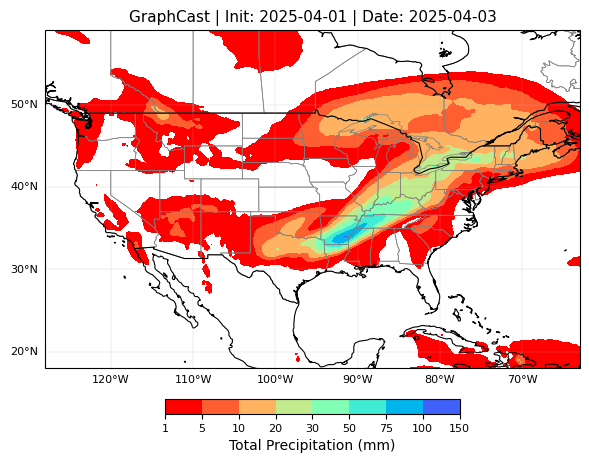

Saved: tn_flood_outputs/graphcast_daily_2025-04-04.png


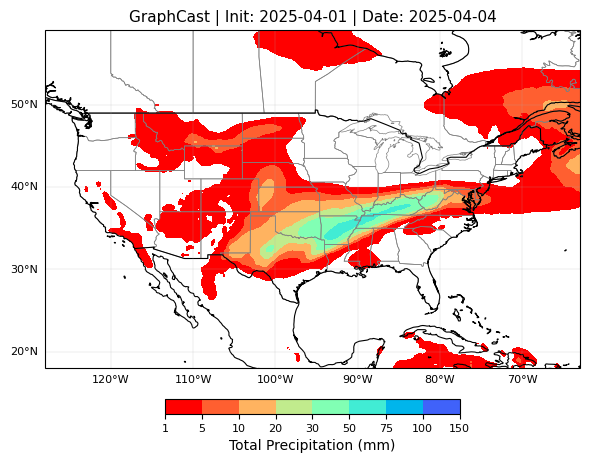

Saved: tn_flood_outputs/graphcast_daily_2025-04-05.png


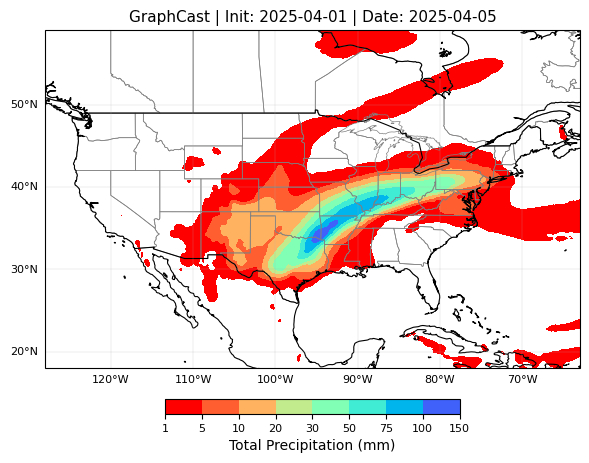

In [7]:
for date in PLOT_DATES:
    precip = compute_daily_total_precip(store, date, FORECAST_INIT)
    plot_daily_precip(
        precip, store, date, EXTENT, FORECAST_INIT,
        save_path=f"{OUTPUT_DIR}/graphcast_daily_{date}.png",
    )

**How to read this.** Each map is one UTC day (00Z to 00Z) of forecast rain from the same 1 April run, so 3 April is a 3-day forecast and 5 April a 5-day forecast. Colours run from red (light, from 1 mm) to blue-purple (heavy, 150 mm and more); white means less than 1 mm. Look at where the heaviest band sits relative to the Tennessee and Ohio valleys and how it shifts from day to day.

Saved: tn_flood_outputs/graphcast_cumulative_apr1_5.png

Cumulative at Nashville: 90.68 mm


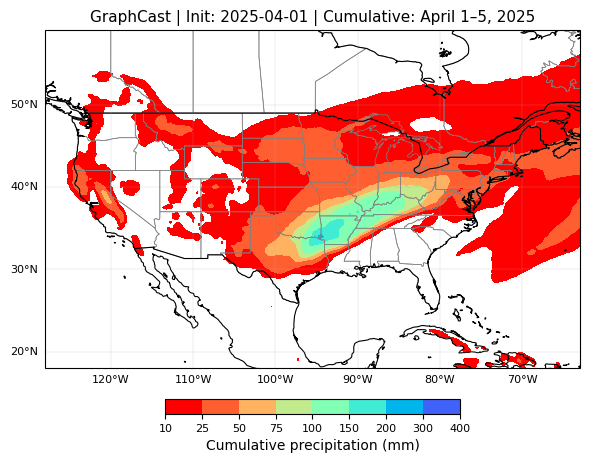

In [9]:
cumulative = compute_cumulative_precip(store, DATES, FORECAST_INIT)

plt.close("all")

lon = store["lon"][:]
lat = store["lat"][:]

levels = [10, 25, 50, 75, 100, 150, 200, 300, 400]
norm = mcolors.BoundaryNorm(levels, PRECIP_CMAP.N, extend="max")

fig, ax = plt.subplots(
    subplot_kw={"projection": ccrs.PlateCarree()},
    figsize=(6, 8),
)

im = ax.contourf(
    lon, lat, cumulative,
    levels=levels, cmap=PRECIP_CMAP, norm=norm,
    transform=ccrs.PlateCarree(), extend="max",
)

ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor="gray")
ax.add_feature(cfeature.BORDERS, linewidth=0.8)
ax.coastlines(linewidth=0.8)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {"size": 8}
gl.ylabel_style = {"size": 8}
ax.set_extent(EXTENT)

cbar = plt.colorbar(im, ax=ax, shrink=0.55, pad=0.04, orientation="horizontal")
cbar.set_label("Cumulative precipitation (mm)", fontsize=10)
cbar.ax.tick_params(labelsize=8)
ax.set_title(
    f"GraphCast | Init: {FORECAST_INIT[:10]} | Cumulative: April 1–5, 2025",
    fontsize=11,
)

plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/graphcast_cumulative_apr1_5.png", dpi=150, bbox_inches="tight")
print(f"Saved: {OUTPUT_DIR}/graphcast_cumulative_apr1_5.png")

plt.show()

**How to read this.** This is the sum of the five daily totals for 1–5 April, on the same red-to-blue-purple scale but with levels from 10 to 400 mm. The flood-producing rain is the long band of large totals; compare its position with the Tennessee Valley box (33–40.5°N, 95–82°W) that is scored in section 7.

## 7 · Verify against ERA5

How close is the forecast to an independent estimate of the rain that fell? Each daily forecast total is compared with the ERA5 daily total for the same UTC window (section 5), over the Tennessee Valley box (33–40.5°N, 95–82°W, `era5_truth.TN_BOX`) on the model's 0.25° grid. Hourly ERA5 precipitation comes from the Copernicus Climate Data Store (it needs `~/.cdsapirc` credentials) and is cached in `OUTPUT_DIR`.

> **Truth caveat:** ERA5 precipitation is itself model-derived (it is a reanalysis product), so these scores measure agreement with ERA5, not with rain gauges or radar.

**How to read the table.** One row per forecast day (lead day 1 = 1 April) plus a row for the 1–5 April total. Bias = forecast − ERA5 in mm/day (positive means too wet), averaged over the box with area weights; RMSE and MAE are the typical size of the point-by-point error in mm/day; Pattern corr = spatial correlation of the daily rainfall pattern (1 means the rain is in the right places, whatever the amounts). The total row is in mm over the five days. The last line compares the area-mean 5-day totals and gives the forecast's percentage bias. Errors usually grow with lead day.

In [ ]:
from era5_truth import TN_ERA5_AREA, fetch_era5_daily_precip, forecast_vs_era5
from metrics import event_total_error, skill_row

era5_daily = fetch_era5_daily_precip(DATES, TN_ERA5_AREA, f"{OUTPUT_DIR}/era5_tp_tn.nc")
lat, lon = store["lat"][:], store["lon"][:]

rows = []
for date in DATES:
    fc, ref, lats = forecast_vs_era5(
        compute_daily_total_precip(store, date, FORECAST_INIT),
        era5_daily.sel(day=np.datetime64(date)), lat, lon,
    )
    lead_day = int((np.datetime64(date) - np.datetime64(FORECAST_INIT[:10])).astype(int)) + 1
    rows.append({"Lead day": lead_day, "Date": date, **skill_row(fc, ref, lats)})

fc_total, ref_total, lats = forecast_vs_era5(
    compute_cumulative_precip(store, DATES, FORECAST_INIT),
    era5_daily.sel(day=[np.datetime64(d) for d in DATES]).sum("day"), lat, lon,
)
rows.append({"Lead day": "Apr 1-5 total", "Date": "", **skill_row(fc_total, ref_total, lats)})

daily_skill = pd.DataFrame(rows)
daily_skill.to_csv(RESULTS_DIR / "graphcast_tennessee_valley_flood_metrics.csv", index=False)
print("GraphCast vs ERA5 over the Tennessee Valley box (mm/day; Bias = forecast - ERA5)\n")
print(daily_skill.to_string(index=False))
print("\nEvent total (area means, mm):", event_total_error(fc_total, ref_total, lats))

## Summary

- **Daily maps (section 6):** where did GraphCast put the heaviest rain on 3–5 April, and how did the band move as the lead time grew?
- **Cumulative map (section 6):** where does the forecast concentrate the 1–5 April total, and does that band cover the Tennessee and Ohio valleys?
- **ERA5 skill table (section 7):** over the Tennessee Valley box, is the forecast too wet or too dry (Bias), how large are the errors (RMSE, MAE), and is the rain in the right places (Pattern corr)? Watch how these change with lead day, and remember that ERA5 precipitation is itself model-derived.

The scores are saved to `docs/results/graphcast_tennessee_valley_flood_metrics.csv`; the map PNGs are in `tn_flood_outputs/`.